# SensorFault-Bench Tutorial

This notebook runs a small version of the benchmark on a CPU in a few
minutes. It shows the eight scored sensor-fault scenarios on one ETTh1 input
window, trains a DLinear baseline and one robustness-improvement method,
evaluates both under all eight scenarios, and reads the reported quantities
from the analysis tables.

The settings are reduced for speed: one dataset, one architecture, two
training epochs, one hyperparameter trial, and 2,000 test windows. The
numbers are therefore not comparable with the results of the default
configuration, as the last section explains.

Run the notebook with the project environment from `uv sync`, for example in
VS Code with the `.venv` kernel or with
`uv run --with jupyterlab jupyter lab` from the repository root.

In [1]:
import os
import subprocess
import sys
import tempfile
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import yaml

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"

REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "run_training.py").is_file()
)
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))

import mlflow

from config_loader import load_defaults
from data.data_module import instantiate_perturbations
from data.datasets import DATASET_REGISTRY
from data.perturbations import PERTURBATION_REGISTRY
from pipelines.training import get_tracking_uri

DEFAULTS = load_defaults()
SCENARIOS = list(DEFAULTS["PERTURBATION_SCENARIOS"])
SCENARIO_LABELS = dict(
    entry.split("=", 1)
    for entry in yaml.safe_load(Path("configs/reporting/core_figures.yaml").read_text())["CORE_SCENARIO_DISPLAY"]
)
METHOD_LABELS = yaml.safe_load(Path("configs/benchmark_scope.yaml").read_text())["methods"]["display_labels"]
LOGDIR = "runs/tutorial"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Scored scenarios:", ", ".join(SCENARIO_LABELS[name] for name in SCENARIOS))

Scored scenarios: Drift, Attenuation, Noise, Spike, TimeStretch, TimeCompress, StuckSensor, MissingData


## 1. Download the data

ETTh1 comes from the ETT archive. The dataset contract checks the row count,
the channels, the hourly timestamps, and the content checksum of the file.

In [2]:
ETTH1_URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"
etth1_path = Path(DEFAULTS["DATA_ROOT"]) / DATASET_REGISTRY.get("ETTh1").path
if not etth1_path.exists():
    etth1_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(ETTH1_URL, etth1_path)


def run(script, *args):
    """Run a repository script and stop with the end of its output on failure."""
    result = subprocess.run([sys.executable, script, *args], capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f"{script} failed:\n{result.stdout[-3000:]}\n{result.stderr[-3000:]}")
    return result


validation = run(
    "scripts/benchmark_dataset_contracts.py",
    "--dataset", "ETTh1",
    "--output", str(etth1_path),
    "--validate-existing",
    "--require-checksums",
)
print(validation.stdout.strip().splitlines()[-1])

{"channels": 7, "content_sha256": "47bf6a7f383b97d7c115d7cdab4fb4e29cf5d4cdd772a63bc35be3125a4baf1f", "dataset": "ETTh1", "filename": "ETTh1.csv", "rows": 17420}


## 2. The eight scored scenarios

Each scenario corrupts the observed input history and leaves the forecast
target unchanged. Value faults act on inputs standardized with the training
statistics. One severity $s \in [0, 1]$ sets the fault magnitude of every
scenario, and scenarios scoped to channels affect a subset of channels that
grows with severity, up to half of the eligible channels.

The panels below apply all eight operators, built as the data module builds
them, to one standardized ETTh1 input window at severity 0.6. The benchmark
draws a new severity for every test window, uniformly from $[0, 1]$.

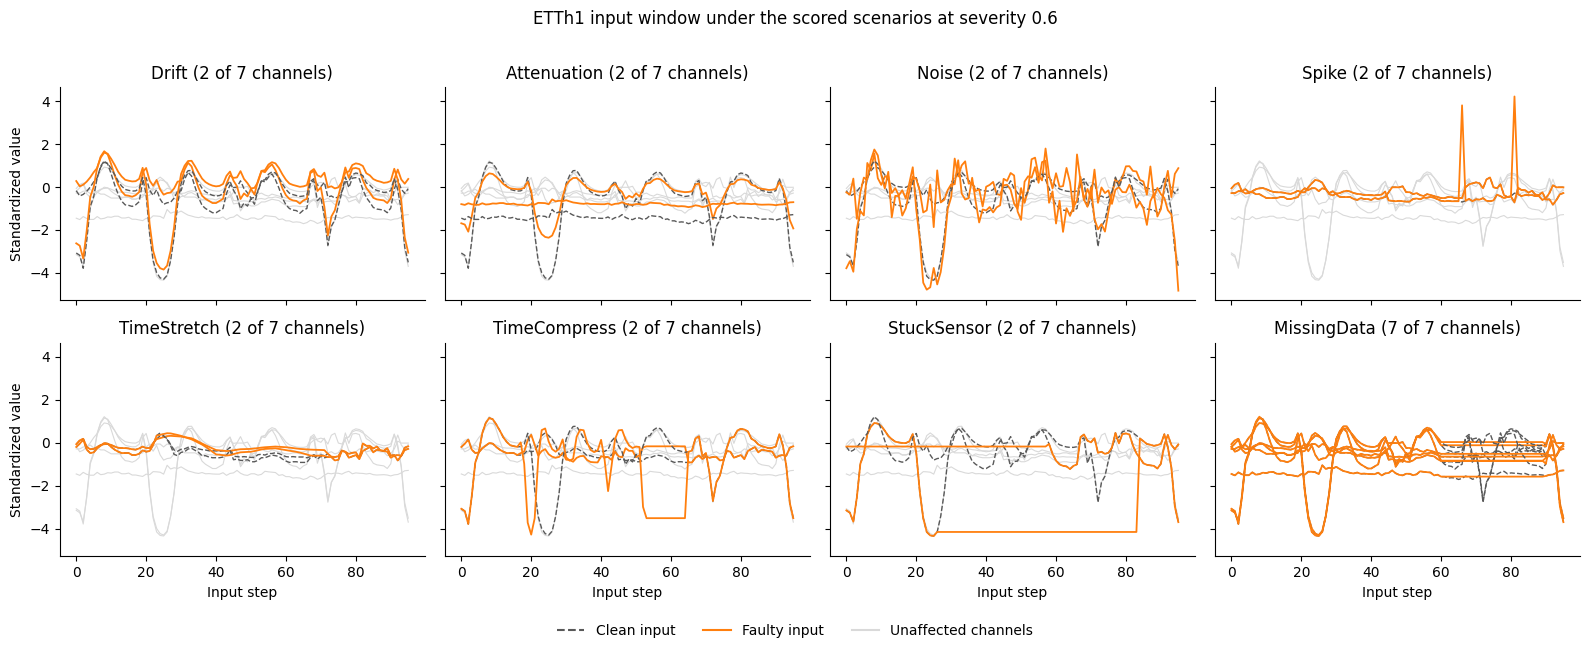

In [3]:
frame = pd.read_csv(etth1_path, index_col=0)
values = frame.to_numpy(dtype="float32")
train_rows = int(len(values) * DEFAULTS["TRAIN_SPLIT"])
standardized = (values - values[:train_rows].mean(axis=0)) / values[:train_rows].std(axis=0)

input_len = target_len = 96
start = int(len(values) * (DEFAULTS["TRAIN_SPLIT"] + DEFAULTS["VAL_SPLIT"])) + 500
x = torch.tensor(standardized[start:start + input_len])
y = torch.tensor(standardized[start + input_len:start + input_len + target_len])
continuous_channels = list(range(x.shape[1]))

operators = instantiate_perturbations(
    [PERTURBATION_REGISTRY[name] for name in SCENARIOS],
    registry=PERTURBATION_REGISTRY,
    channel_fraction_max=DEFAULTS["PERTURBATION_CHANNEL_FRACTION_MAX"],
)
severity = 0.6
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True, sharey=True)
for index, (name, operator, ax) in enumerate(zip(SCENARIOS, operators, axes.flat)):
    faulty, target, affected = operator(
        x, y, severity, torch.Generator().manual_seed(index), continuous_channels, []
    )
    assert torch.equal(target, y), "Faults must not change the forecast target."
    for channel in range(x.shape[1]):
        if channel not in affected:
            ax.plot(x[:, channel], color="0.85", linewidth=0.8)
    for channel in affected:
        ax.plot(x[:, channel], color="0.35", linestyle="--", linewidth=1.0)
        ax.plot(faulty[:, channel], color="tab:orange", linewidth=1.3)
    ax.set_title(f"{SCENARIO_LABELS[name]} ({len(affected)} of {x.shape[1]} channels)")
for ax in axes[1]:
    ax.set_xlabel("Input step")
for ax in axes[:, 0]:
    ax.set_ylabel("Standardized value")
fig.legend(
    handles=[
        plt.Line2D([], [], color="0.35", linestyle="--", label="Clean input"),
        plt.Line2D([], [], color="tab:orange", label="Faulty input"),
        plt.Line2D([], [], color="0.85", label="Unaffected channels"),
    ],
    loc="lower center", ncol=3, frameon=False,
)
fig.suptitle(f"ETTh1 input window under the scored scenarios at severity {severity}")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
plt.show()

## 3. Train, test, and analyze a small benchmark

The three entry points run the benchmark workflow: training with
hyperparameter search, selection on clean validation data and evaluation
under all eight scenarios, and the cross-run analysis. The scope here is
ETTh1, DLinear, the baseline, and randomized training, whose three noise
levels form its search grid. `--accelerator cpu --num-workers 0` keeps the
run fast on a CPU, and the run store lives in `runs/tutorial`.

Testing uses `--full-coverage`, so a missing selected model stops the run.
The analysis runs without it, because the core figures of the benchmark need
all four datasets. It then writes every table and leaves out the figures it
cannot build.

In [4]:
SCOPE = [
    "--data-files", "ETTh1",
    "--model", "DLinear",
    "--method", "baseline", "randomized_training",
    "--logdir", LOGDIR,
    "--mlflow-experiment-prefix", "tutorial",
    "--max-hp-trials-per-model", "1",
    "--accelerator", "cpu",
    "--num-workers", "0",
]
TEST_WINDOWS = ["--n-test-samples", "2000"]

run("run_training.py", *SCOPE, "--max-epochs", "2")
run("run_testing.py", *SCOPE, *TEST_WINDOWS, "--full-coverage")
run("run_analysis.py", *SCOPE, *TEST_WINDOWS)
print("Training, testing, and analysis finished.")

Training, testing, and analysis finished.


## 4. Read the reported quantities

The analysis run stores its tables as MLflow artifacts. `full_results.csv`
has one row per selected model with the three reported quantities:

- clean MSE (`MSE_test`): test MSE on unperturbed input histories,
- worst-scenario degradation (`D_w`): the largest scenario degradation
  $\mathcal{D}_p = \mathrm{MSE}_p / \mathrm{MSE}_c$, with its 95% bootstrap
  interval,
- worst-scenario fault-time MSE (`MSE_w`): test MSE under that worst
  scenario.

Relative robustness and absolute error answer different questions, so the
benchmark reports them side by side.

In [5]:
tracking_uri = get_tracking_uri(LOGDIR)
client = mlflow.MlflowClient(tracking_uri)
analysis_experiment = client.get_experiment_by_name("Meta Analysis")
(analysis_run,) = client.search_runs(
    [analysis_experiment.experiment_id], order_by=["attributes.start_time DESC"], max_results=1
)
tables = Path(mlflow.artifacts.download_artifacts(
    run_id=analysis_run.info.run_id,
    artifact_path="tables",
    dst_path=tempfile.mkdtemp(),
    tracking_uri=tracking_uri,
))
results = pd.read_csv(tables / "full_results.csv")
results[[
    "model_architecture", "robustness_method", "pipeline_id",
    "MSE_test", "D_w", "D_w_CI_lo", "D_w_CI_hi", "MSE_w", "worst_scenario",
]].round(3)

,model_architecture,robustness_method,pipeline_id,MSE_test,D_w,D_w_CI_lo,D_w_CI_hi,MSE_w,worst_scenario
0,DLinear,randomized_training,rt_spaceraw_std0.1_channelscontinuous,0.453,1.212,1.195,1.231,0.549,stuck_sensor
1,DLinear,baseline,baseline,0.454,1.210,1.192,1.229,0.550,stuck_sensor


`scenario_summary.csv` holds the degradation of every selected model in every
scenario. Its maximum per model is the worst-scenario degradation above.

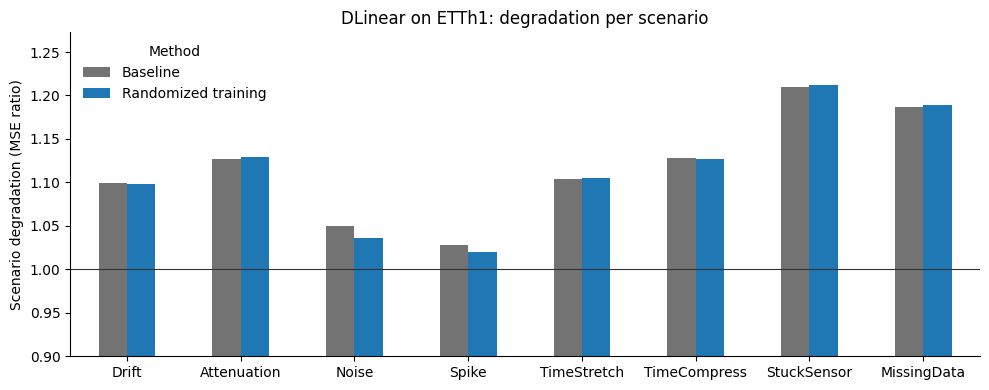

In [6]:
summary = pd.read_csv(tables / "scenario_summary.csv")
summary = summary[summary["run_id"].isin(results["run_id"])]
for _, row in results.iterrows():
    worst = summary[summary["run_id"] == row["run_id"]]["D"].max()
    assert abs(worst - row["D_w"]) < 1e-9, "D_w is the maximum scenario degradation."

degradation = (
    summary.pivot_table(index="scenario", columns="robustness_method", values="D")
    .reindex(SCENARIOS)
    .rename(index=SCENARIO_LABELS, columns=METHOD_LABELS)
)
ax = degradation.plot.bar(figsize=(10, 4), rot=0, color=["0.45", "tab:blue"])
ax.axhline(1.0, color="0.2", linewidth=0.8)
ax.set_ylim(bottom=0.9)
ax.set_ylabel("Scenario degradation (MSE ratio)")
ax.set_xlabel("")
ax.set_title("DLinear on ETTh1: degradation per scenario")
ax.legend(title="Method", frameon=False)
plt.tight_layout()
plt.show()

Every test window draws its own severity. `scenario_samples.csv` records the
severity and the errors of each window, which shows how the degradation of
the baseline grows with severity in each scenario.

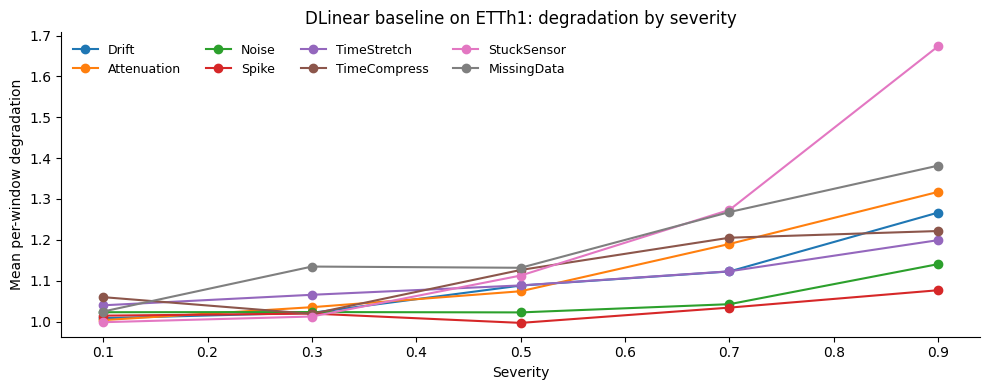

In [7]:
samples = pd.read_csv(tables / "scenario_samples.csv")
baseline_run = results.loc[results["robustness_method"] == "baseline", "run_id"].item()
baseline_samples = samples[samples["run_id"] == baseline_run].copy()
baseline_samples["severity_bin"] = pd.cut(baseline_samples["severity"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
by_severity = baseline_samples.groupby(["scenario", "severity_bin"], observed=True)["D"].mean().unstack("scenario")

fig, ax = plt.subplots(figsize=(10, 4))
centers = [interval.mid for interval in by_severity.index]
for name in SCENARIOS:
    ax.plot(centers, by_severity[name], marker="o", label=SCENARIO_LABELS[name])
ax.set_xlabel("Severity")
ax.set_ylabel("Mean per-window degradation")
ax.set_title("DLinear baseline on ETTh1: degradation by severity")
ax.legend(ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 5. Compare the method with its baseline

Each robustness-improvement method is compared with the paired baseline
forecasting model of the same dataset and architecture. The deltas are
method minus baseline, so negative values indicate improvement. The full
benchmark averages these deltas over five architectures per dataset and
adds bootstrap intervals over the architecture pairs.

On ETTh1, randomized training changes DLinear only slightly, in this small run
as in the full benchmark. The method reduces degradation most on Beijing Air
Tiantan, where value faults dominate the observed degradation (Table 4 of the
paper).

In [8]:
deltas = pd.read_csv(tables / "improvement_deltas_selected.csv")
deltas[[
    "model_architecture", "robustness_method", "pipeline_id",
    "delta_MSE_test", "delta_D_w", "delta_MSE_w",
]].round(3)

,model_architecture,robustness_method,pipeline_id,delta_MSE_test,delta_D_w,delta_MSE_w
0,DLinear,randomized_training,rt_spaceraw_std0.1_channelscontinuous,-0.001,0.002,-0.001


## 6. A forecast under a fault

`scripts/render_forecast_plots.py from-runs` rebuilds one test window from
the run store, applies its recorded fault, and exports the clean and faulty
forecasts. The window below is the StuckSensor window with the largest
degradation of the baseline among severities between 0.3 and 0.6.

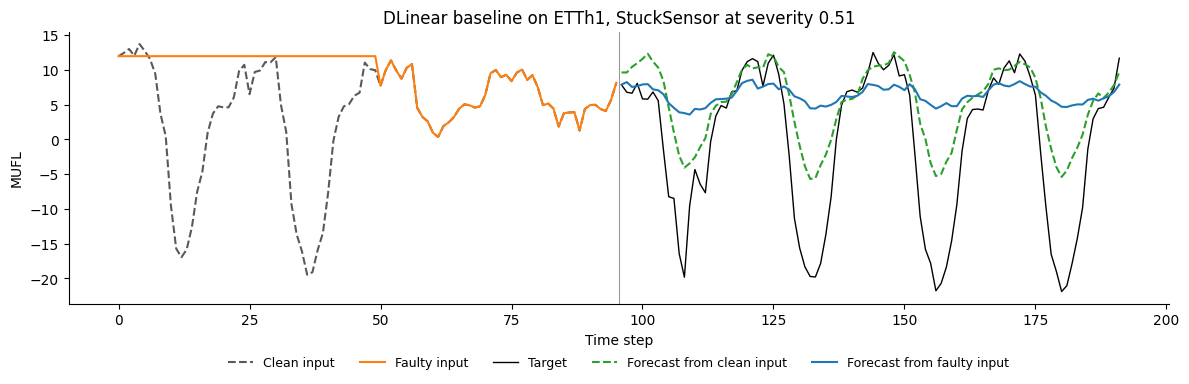

In [9]:
stuck = baseline_samples[
    (baseline_samples["scenario"] == "stuck_sensor")
    & baseline_samples["severity"].between(0.3, 0.6)
]
window = stuck.loc[stuck["D"].idxmax()]
sample = ":".join(str(value) for value in (
    "DLinear", "stuck_sensor", int(window["pert_idx"]), int(window["sample_id"]),
    int(window["source_sample_idx"]), float(window["severity"]),
))
baseline_row = results[results["robustness_method"] == "baseline"].iloc[0]
forecast_dir = Path(LOGDIR) / "forecast_example"
run(
    "scripts/render_forecast_plots.py", "from-runs",
    "--tracking-uri", LOGDIR,
    "--experiment-prefix", "tutorial",
    "--data-root", DEFAULTS["DATA_ROOT"],
    "--dataset", "ETTh1",
    "--model", "DLinear",
    "--method", "baseline",
    "--n-test-samples", "2000",
    "--eval-data-seed", str(int(baseline_row["eval_data_seed"])),
    "--batch-size", "16",
    "--accelerator", "cpu",
    "--format", "html",
    "--sample", sample,
    "--output-dir", str(forecast_dir),
)
(trace_path,) = sorted(forecast_dir.rglob("*stuck_sensor*.csv"))
trace = pd.read_csv(trace_path)

feature = trace.loc[trace["affected_feature"], "feature"].iloc[0]
rows = trace[trace["feature"] == feature]
history = rows[rows["segment"] == "input"]
horizon = rows[rows["segment"] == "forecast"]
steps = history["time_step"].to_numpy()
future = horizon["time_step"].to_numpy() + len(history)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(steps, history["clean_input"], color="0.35", linestyle="--", label="Clean input")
ax.plot(steps, history["perturbed_input"], color="tab:orange", label="Faulty input")
ax.plot(future, horizon["ground_truth"], color="black", linewidth=1.0, label="Target")
ax.plot(future, horizon["clean_prediction"], color="tab:green", linestyle="--", label="Forecast from clean input")
ax.plot(future, horizon["perturbed_prediction"], color="tab:blue", label="Forecast from faulty input")
ax.axvline(len(history) - 0.5, color="0.6", linewidth=0.8)
ax.set_xlabel("Time step")
ax.set_ylabel(f"{feature}")
ax.set_title(f"DLinear baseline on ETTh1, StuckSensor at severity {float(window['severity']):.2f}")
ax.legend(ncol=5, frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()

## 7. Compare with the default configuration

The DLinear baseline of the default configuration on ETTh1 used the same data
split. Its data configuration signature matches the one recorded for ETTh1 in
`paper_artifact/MANIFEST.json`. The numbers still differ because the default
configuration searches up to 40 hyperparameter configurations, trains up to
200 epochs with early stopping, and evaluates on 10,000 test windows. Results
are comparable with the default configuration only under its settings, as the
README section "Evaluating a new model or method" states. Table 4 of the paper
reports the results of the default configuration on all four datasets.

In [10]:
manifest = yaml.safe_load(Path("paper_artifact/MANIFEST.json").read_text())
default_results = pd.read_csv("paper_artifact/paper_inputs/main_table_backbone.csv")
default_row = default_results[
    (default_results["dataset"] == "ETTh1") & (default_results["backbone"] == "DLinear")
].iloc[0]

print(
    "Same data split as the default configuration:",
    baseline_row["data_config_signature"] in manifest["data_config_signatures"]["ETTh1"],
)
pd.DataFrame(
    {
        "This notebook": [baseline_row["MSE_test"], baseline_row["D_w"], baseline_row["MSE_w"]],
        "Default configuration": [default_row["MSE_c"], default_row["D_w"], default_row["MSE_w"]],
    },
    index=["Clean MSE", "Worst-scenario degradation", "Worst-scenario fault-time MSE"],
).round(3)

Same data split as the default configuration: True


,This notebook,Default configuration
Clean MSE,0.454,0.438
Worst-scenario degradation,1.210,1.251
Worst-scenario fault-time MSE,0.550,0.548


## Next steps

- Inspect every run with `uv run mlflow ui --backend-store-uri runs/tutorial`.
- Run the full benchmark with the commands in the README section
  "Reproducing the paper".
- Add a dataset, forecasting architecture, or robustness-improvement method
  with the guides in `docs/`, and follow the README section "Evaluating a
  new model or method".